# Data Import . Testing the Hypothetical Synchrotron Plugin


In [6]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# walk upward from this notebook until we find the project root
# (identified by the presence of the data_import folder)
here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: d:\GitHub\Universial-Reconstructions


In [4]:
from data_import.importer import DataImporter
from core.data_interface import DataInterface

importer = DataImporter()
project = importer.import_project(project_root / "tests/fixtures/generated/hypothetical_synchrotron.h5", format="hdf5", storage_mode="disk")
print(project)

di = DataInterface(project)
print(di.get_projections().shape)   # should be (800, 256, 512)

ProjectObject(format=hdf5, storage_mode=disk, vendor=hypothetical_synchrotron_hdf5, handles=['projections', 'flats'])
(200, 128, 192)


In [5]:
di.get_metadata('angles')  # should be a dict with keys 'angles', 'angles_unit', 'pixel_size', 'pixel_size_unit'


array([  0. ,   0.9,   1.8,   2.7,   3.6,   4.5,   5.4,   6.3,   7.2,
         8.1,   9. ,   9.9,  10.8,  11.7,  12.6,  13.5,  14.4,  15.3,
        16.2,  17.1,  18. ,  18.9,  19.8,  20.7,  21.6,  22.5,  23.4,
        24.3,  25.2,  26.1,  27. ,  27.9,  28.8,  29.7,  30.6,  31.5,
        32.4,  33.3,  34.2,  35.1,  36. ,  36.9,  37.8,  38.7,  39.6,
        40.5,  41.4,  42.3,  43.2,  44.1,  45. ,  45.9,  46.8,  47.7,
        48.6,  49.5,  50.4,  51.3,  52.2,  53.1,  54. ,  54.9,  55.8,
        56.7,  57.6,  58.5,  59.4,  60.3,  61.2,  62.1,  63. ,  63.9,
        64.8,  65.7,  66.6,  67.5,  68.4,  69.3,  70.2,  71.1,  72. ,
        72.9,  73.8,  74.7,  75.6,  76.5,  77.4,  78.3,  79.2,  80.1,
        81. ,  81.9,  82.8,  83.7,  84.6,  85.5,  86.4,  87.3,  88.2,
        89.1,  90. ,  90.9,  91.8,  92.7,  93.6,  94.5,  95.4,  96.3,
        97.2,  98.1,  99. ,  99.9, 100.8, 101.7, 102.6, 103.5, 104.4,
       105.3, 106.2, 107.1, 108. , 108.9, 109.8, 110.7, 111.6, 112.5,
       113.4, 114.3,

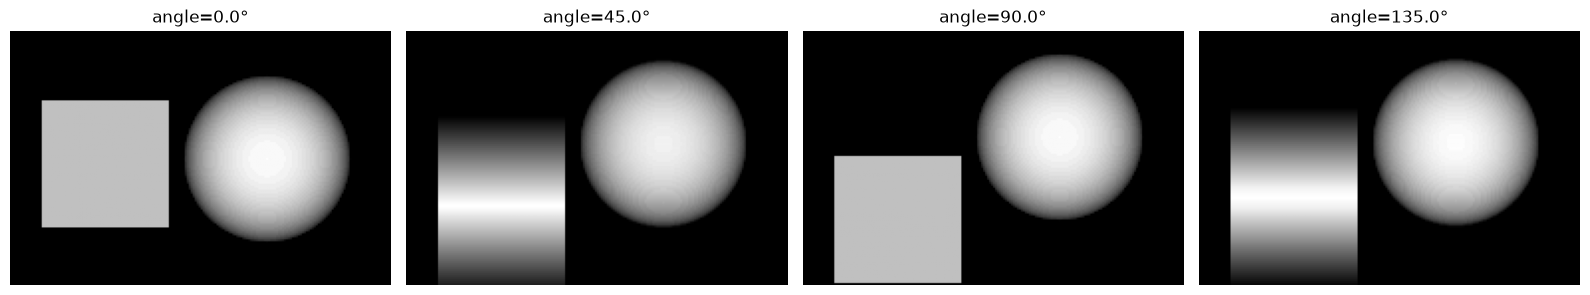

In [7]:
angles = di.get_metadata("angles")
n = len(angles)
indices = [0, n // 4, n // 2, 3 * n // 4]

fig, axes = plt.subplots(1, len(indices), figsize=(16, 4))
for ax, i in zip(axes, indices):
    ax.imshow(di.get_projections(index=i), cmap="gray")
    ax.set_title(f"angle={angles[i]:.1f}°")
    ax.axis("off")
plt.tight_layout()
plt.show()